# Task 4 — Open-Ended Business Analytics Solution

Proposed solution: business sales and customer analytics. Add the official Task 4 dataset to `data/raw/` with `sales`, `business` or `customer` in the filename. Confirm that this project matches the official Task 4 brief before submission.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / "data" / "raw"
files = list(DATA.glob("*.csv")) + list(DATA.glob("*.xlsx")) + list(DATA.glob("*.json"))
print("Data files found:", [f.name for f in files])
print("Task 4 dataset: Business sales and customer analytics. Validate currency, units, returns, and data quality before drawing business conclusions.")

def load_data(keywords):
    matches = [f for f in files if any(k in f.name.lower() for k in keywords)]
    if not matches:
        print("DATASET MISSING for:", keywords)
        return None
    f = matches[0]
    print("Loading:", f.name)
    if f.suffix.lower() == ".csv":
        return pd.read_csv(f)
    if f.suffix.lower() == ".xlsx":
        return pd.read_excel(f)
    return pd.read_json(f)

def overview(df):
    if df is None:
        return
    print("Shape:", df.shape)
    display(df.head())
    display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing"))
    display(df.describe(include="all").T)

df = load_data(['sales', 'business', 'customer'])
overview(df)

Data files found: ['zomato.csv', 'loan_approval_dataset.csv', 'instagram_analytics.csv', 'business_sales_customers.csv']
Task 4 dataset: Business sales and customer analytics. Validate currency, units, returns, and data quality before drawing business conclusions.
Loading: business_sales_customers.csv
Shape: (30000, 41)


,Order_ID,Customer_ID,Order_Date,Year,Month,Day,Day_Of_Week,Quarter,Customer_Age,Customer_Gender,...,Delivery_Days,Order_Status,Returned,Review_Rating,Customer_Lifetime_Value,Profit_Margin_Percent,Profit_Amount,Season,Holiday_Season,High_Value_Order
0,615717,CUST007322,2023-01-01,2023,1,1,Sunday,1,32,Male,...,2,Delivered,No,4.4,2144.92,23.10,15.75,Winter,No,No
1,626919,CUST004717,2023-01-01,2023,1,1,Sunday,1,50,Male,...,9,Delivered,No,4.1,817.17,8.57,3.32,Winter,No,No
2,615781,CUST004415,2023-01-01,2023,1,1,Sunday,1,61,Male,...,2,Delivered,No,5.0,541.16,29.72,45.67,Winter,No,No
3,621747,CUST004114,2023-01-01,2023,1,1,Sunday,1,34,Male,...,6,Returned,Yes,3.4,700.49,25.22,75.25,Winter,No,No
4,625881,CUST000145,2023-01-01,2023,1,1,Sunday,1,37,Male,...,8,Delivered,No,3.6,2133.77,24.64,26.06,Winter,No,No


,missing
Order_ID,0
Customer_ID,0
Order_Date,0
Year,0
Month,0
Day,0
Day_Of_Week,0
Quarter,0
Customer_Age,0
Customer_Gender,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,30000.0,NaN,NaN,NaN,615000.5,8660.398374,600001.0,607500.75,615000.5,622500.25,630000.0
Customer_ID,30000,8683,CUST000031,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Date,30000,1461,2024-03-09,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,30000.0,NaN,NaN,NaN,2024.4947,1.118815,2023.0,2023.0,2024.0,2025.0,2026.0
Month,30000.0,NaN,NaN,NaN,6.5315,3.460955,1.0,4.0,7.0,10.0,12.0
Day,30000.0,NaN,NaN,NaN,15.7236,8.779714,1.0,8.0,16.0,23.0,31.0
Day_Of_Week,30000,7,Monday,4327,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quarter,30000.0,NaN,NaN,NaN,2.507,1.118806,1.0,2.0,3.0,4.0,4.0
Customer_Age,30000.0,NaN,NaN,NaN,36.3703,11.315534,18.0,28.0,36.0,44.0,75.0
Customer_Gender,30000,3,Female,14863,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## KPI and trend exploration

Numeric KPI candidates: ['Order_ID', 'Year', 'Month', 'Day', 'Quarter', 'Customer_Age', 'Unit_Price', 'Quantity', 'Discount_Percent', 'Discount_Amount', 'Shipping_Cost', 'Tax_Amount', 'Order_Amount', 'Delivery_Days', 'Review_Rating', 'Customer_Lifetime_Value', 'Profit_Margin_Percent', 'Profit_Amount']
Order_ID: sum=18,450,015,000.00; mean=615,000.50
Year: sum=60,734,841.00; mean=2,024.49
Month: sum=195,945.00; mean=6.53
Day: sum=471,708.00; mean=15.72
Quarter: sum=75,210.00; mean=2.51
Customer_Age: sum=1,091,109.00; mean=36.37
Unit_Price: sum=3,804,604.44; mean=126.82
Quantity: sum=92,420.00; mean=3.08
Date candidates: ['Order_Date']


,Order_ID
_date,
2023-01,440066246
2023-02,356704348
2023-03,398689999
2023-04,352331143
2023-05,389175871
2023-06,381587303
2023-07,386666234
2023-08,391151505
2023-09,388545596


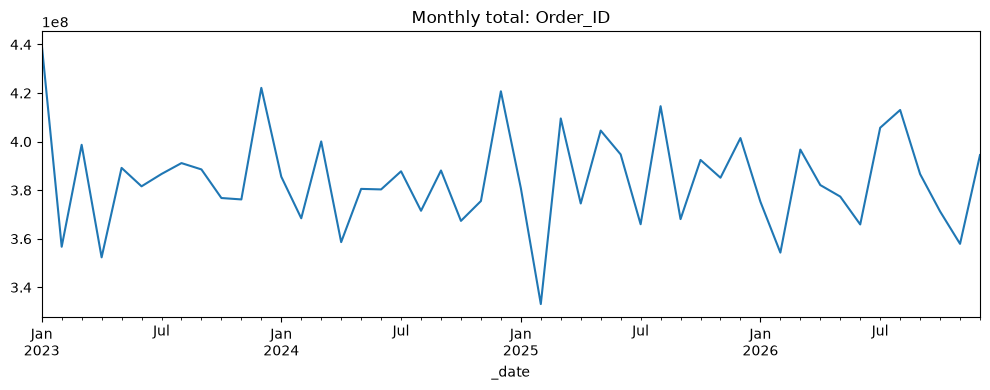

Validate currency, units, duplicate orders, returns and missing values before conclusions.


In [2]:
if df is not None:
    numeric = df.select_dtypes(include="number")
    print("Numeric KPI candidates:", list(numeric.columns))
    for col in numeric.columns[:8]:
        print(f"{col}: sum={numeric[col].sum():,.2f}; mean={numeric[col].mean():,.2f}")
    date_cols = [c for c in df.columns if any(
        k in c.lower() for k in ["date", "order_time", "timestamp"]
    )]
    if date_cols:
        print("Date candidates:", date_cols)
        parsed = pd.to_datetime(df[date_cols[0]], errors="coerce")
        if parsed.notna().any() and len(numeric.columns):
            tmp = df.assign(_date=parsed).dropna(subset=["_date"])
            metric = numeric.columns[0]
            trend = tmp.groupby(tmp["_date"].dt.to_period("M"))[metric].sum()
            display(trend.to_frame(metric))
            trend.plot(title=f"Monthly total: {metric}", figsize=(10, 4))
            plt.tight_layout()
            plt.show()
    print("Validate currency, units, duplicate orders, returns and missing values before conclusions.")
else:
    print("Dataset missing. Add the official data before writing findings.")

## Business recommendations

Use measured KPIs to identify opportunities, quantify limitations and recommend a testable action. Include the dataset source, assumptions, evaluation method and reproducible steps.